# Strings

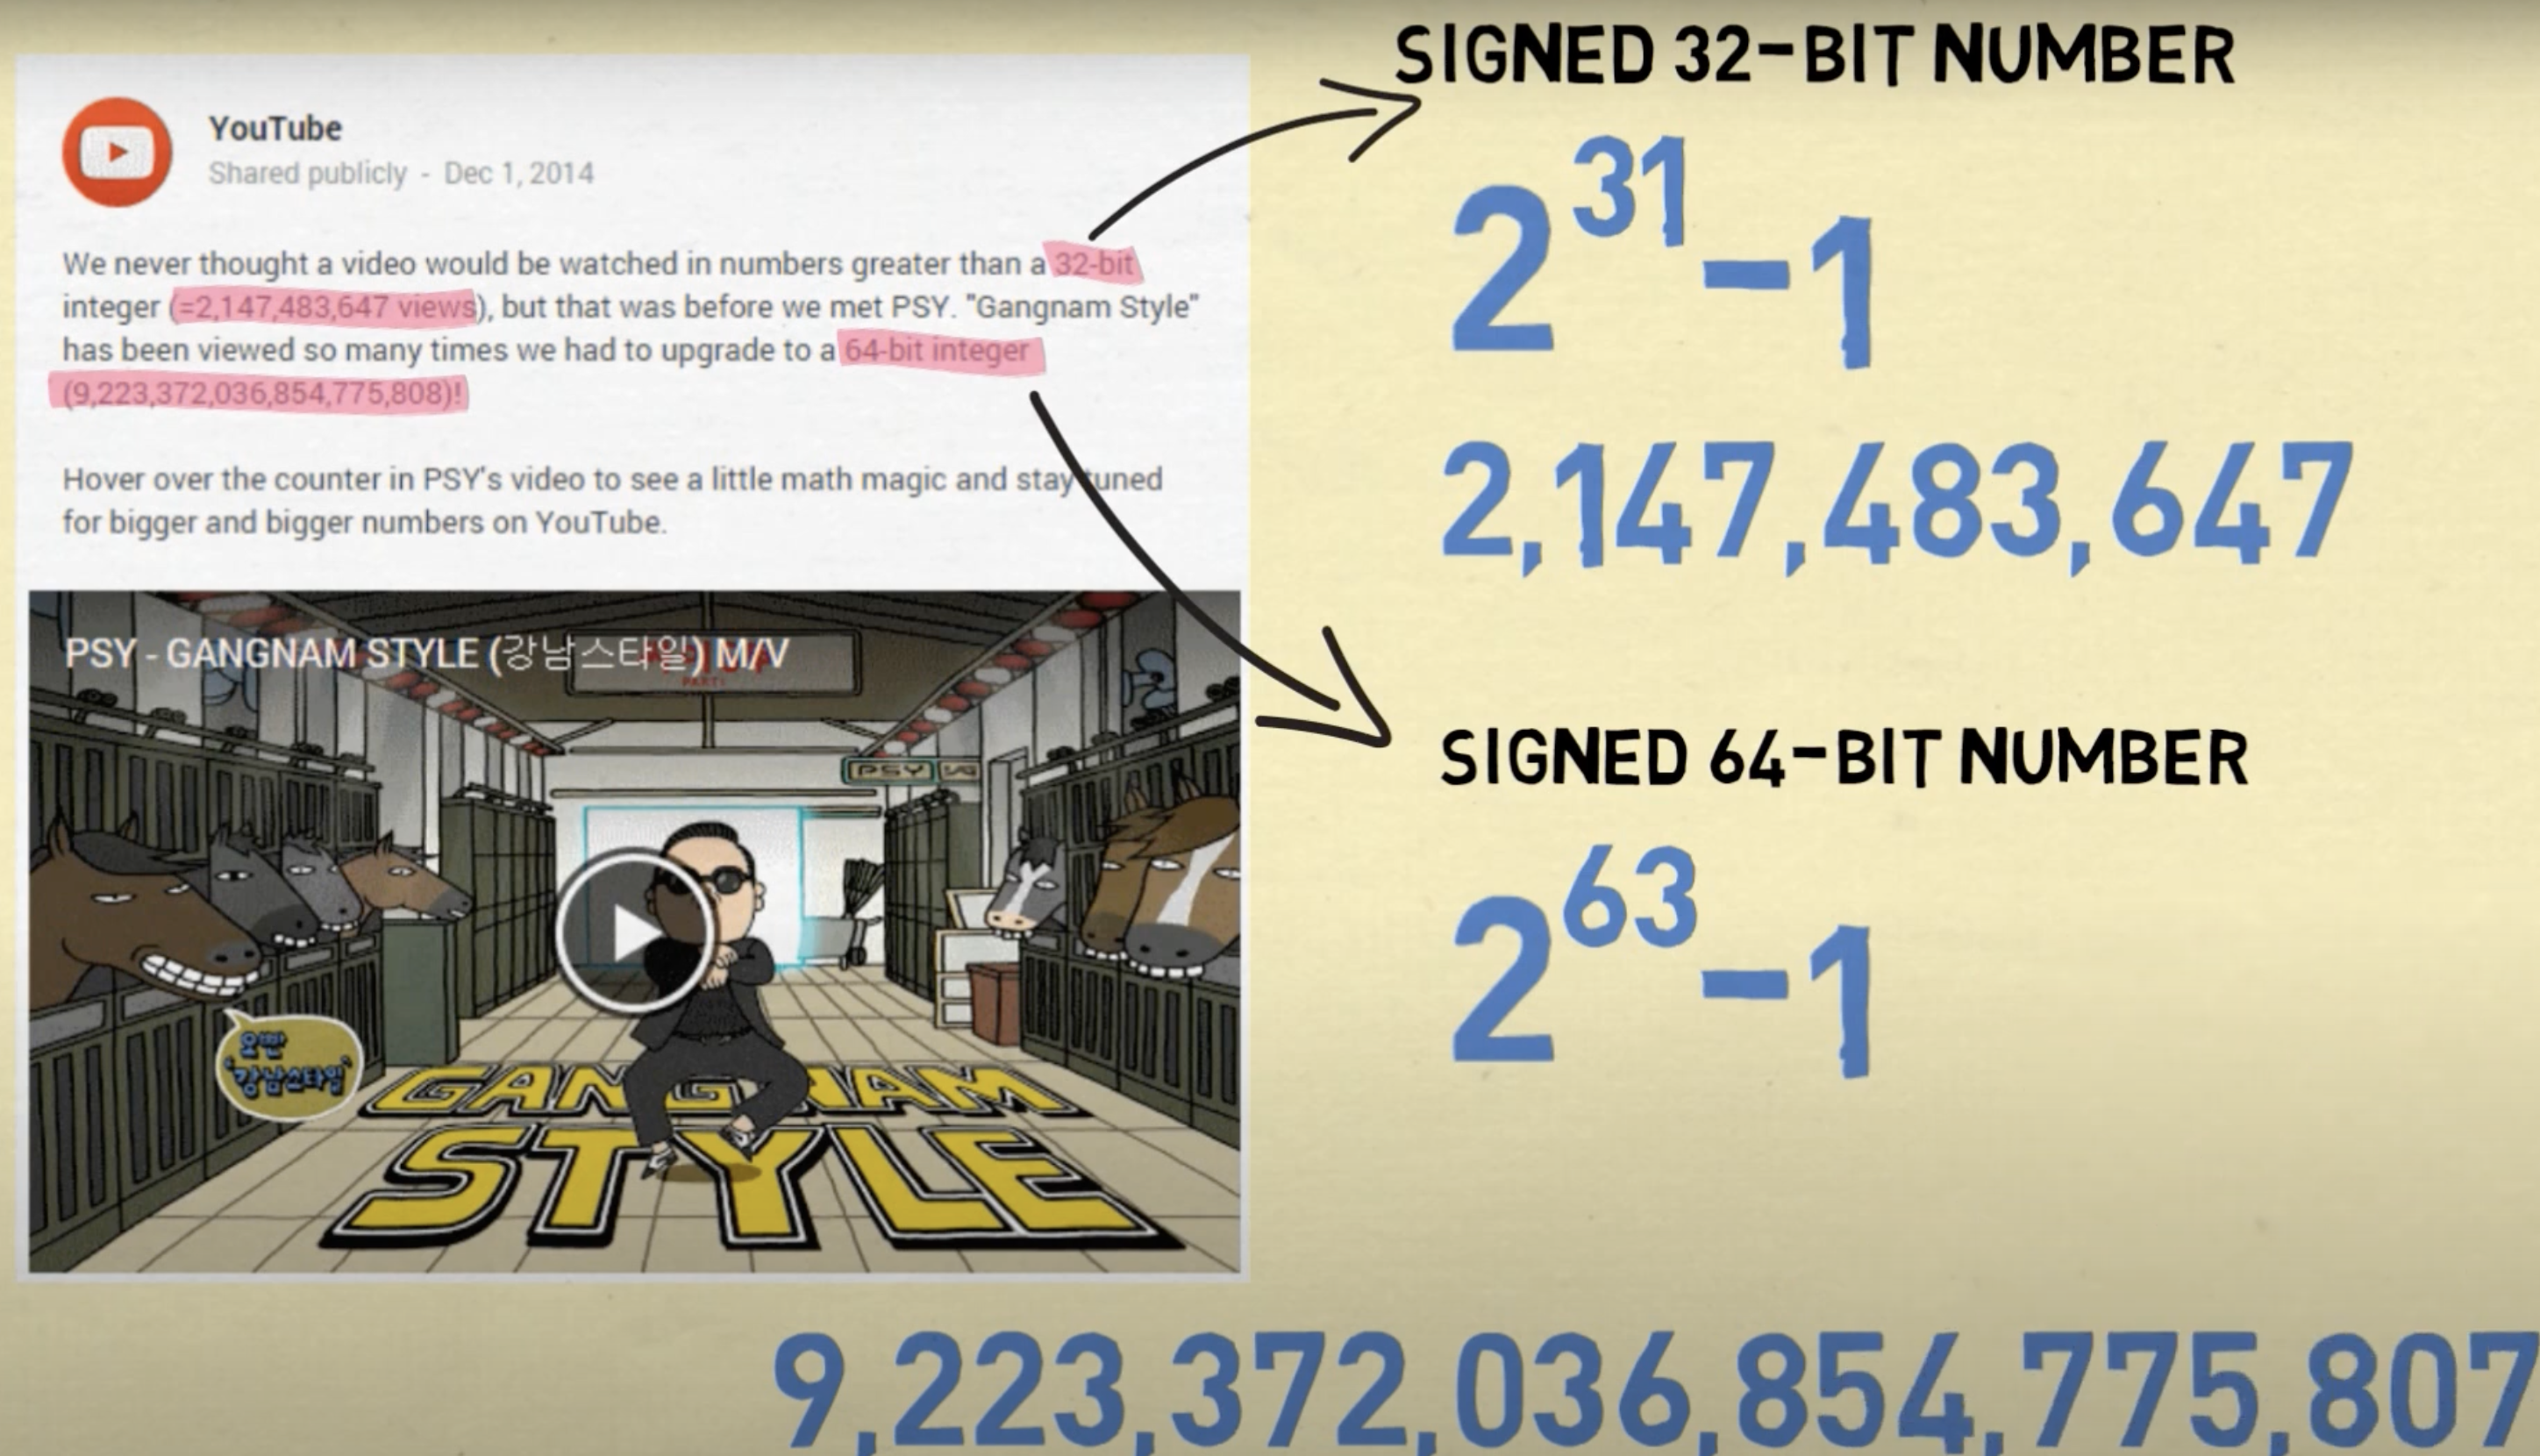

# Strings

```c
char *p = "abcde" vs. char s[] = "abcde"
```

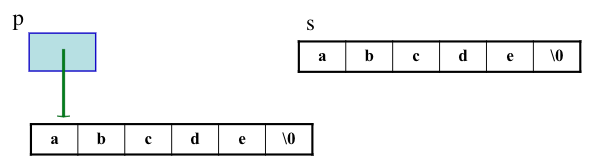

## Example 1

```c
char *p = “abcde”
printf( “%s %s\n”, p, p +1 );

char s[] = “abcde”
/*	is equivalent to: */
char s[] = {‘a’, ‘b’, ‘c’, ‘d’, ‘e’, ‘\0’};


```c
#include <stdio.h>

int main() {
    char *p = "abcde";
    printf("%s\n", p); /* Prints: abcde*/
    p[0] = 'x';      /* Undefined behavior! Segmentation fault.*/
    printf("%s\n", p);
    return 0;
}
```

```c
#include <stdio.h>

int main() {
    char s[] = "abcde";
    printf("%s\n", s); // Prints: abcde
    s[0] = 'x';        // Modifies the array.
    printf("%s\n", s); // Prints: xbcde
    return 0;
}
```

In [ ]:
# @title
%%writefile tmp.c
#include <stdio.h>
#include <ctype.h>

int word_cnt(char *s);

int main()
{
    char str[100];

    printf("Enter a string: ");
    fgets(str, sizeof(str), stdin);

    int count = word_cnt(str);

    printf("The string contains %d words.\n", count);

    return 0;
}

int word_cnt(char *s)
{
    int cnt = 0;
    while (*s != '\0')
    {
        while (isspace(*s))
            ++s;
        if (*s != '\0')
        {
            ++cnt;
            while (!isspace(*s) && *s != '\0')
                ++s;
        }
    }
    return cnt;
}

In [ ]:
# @title
!gcc tmp.c -o tmp
!./tmp

## Strings in the standard library

The `<string.h>` library provides functions for handling and manipulating strings in C.

```c
#include <string.h>

char *strcat(char *s1, const char *s2);

int strcmp(const char *s1, const char *s2);

char *strcpy(char *s1, const char *s2);

unsigned strlen(const char *s);
```

## An implementation example (1)

```c
unsigned strlen(const char *s)
{
    int n = 0;

    for (; *s != '\0'; ++s)
        ++n;
    return n;
}
```

In [ ]:
# @title
%%writefile tmp.c
#include <stdio.h>
#include <string.h>
int main()
{

    char s[] = "Hello";
    unsigned len = strlen(s);
    printf("The length of the string is: %u\n", len);
    return 0;
}


In [ ]:
# @title
!gcc tmp.c -o tmp
!./tmp

## An implementation example (2)

```c
char *strcat(char *s1, const char *s2)
{
    char *p = s1;

    while (*p)
        ++p;

    while (*p++ = *s2++);

    return s1;
}
```

**Why Return s1?**

## String permutations

Goal: print all permutations of a given string.

Example: “ABC” -> ABC,ACB,BAC,BCA,CAB,CBA

Can you think of a recursive solution?


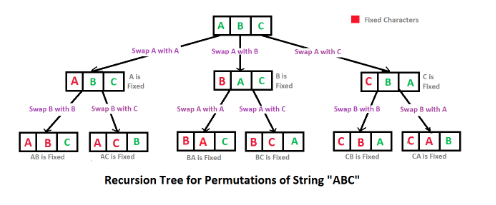

## Implementation (swap)

```c
void swap(char *x, char *y)
{
    char temp;
    temp = *x;
    *x = *y;
    *y = temp;
}
```

## Implementation (recursion)

```c
void permute(char *a, int l, int r)
{
    int i;
    if (l == r)
        printf("%s\n", a);
    else
    {
        for (i = l; i <= r; i++)
        {
            swap((a + l), (a + i));
            permute(a, l + 1, r);
            swap((a + l), (a + i)); // backtrack
        }
    }
}
```

## Ragged Arrays

```c
    char a[2][15] = {"abc:", "a is for apple"};
    char *p[2] = {"abc:", "a is for apple"};

    printf("%c%c%c %s %s\n%c%c%c %s %s\n",
           a[0][0],
           a[0][1], a[0][2], a[0], a[1], p[0][0], p[0][1], p[0][2], p[0], p[1]);

```

In [ ]:
# @title
%%writefile tmp.c
#include <stdio.h>
int main(void)
{
    char a[2][15] = {"abc:", "a is for apple"};
    char *p[2] = {"abc:", "a is for apple"};

    printf("%c%c%c %s %s\n%c%c%c %s %s\n",
           a[0][0],
           a[0][1], a[0][2], a[0], a[1], p[0][0], p[0][1], p[0][2], p[0], p[1]);
    return 0;
}


In [ ]:
# @title
!gcc -o tmp tmp.c
!./tmp